# **Lab 7(A) - Laplacian Filter**

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

# Load a color image (OpenCV reads BGR) and convert it to RGB
imgFile = "images/parrot.png"  # Replace with your color image filename
img_bgr = cv2.imread(imgFile, cv2.IMREAD_COLOR)

if img_bgr is None:
    raise FileNotFoundError(f"Could not load {imgFile}. Put the image in the notebook folder.")

img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)


## Apply Laplacian Filter on Image to get Sharp Image

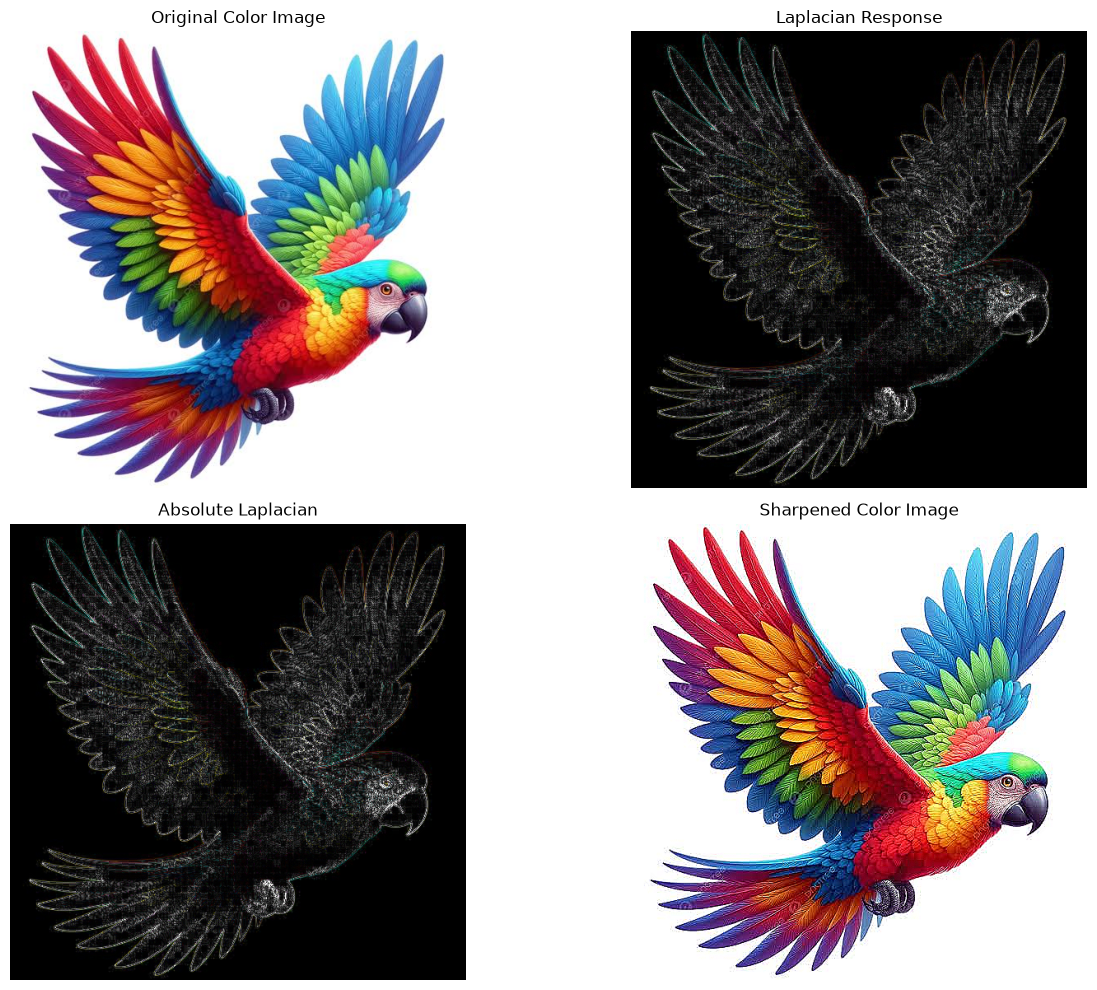

In [2]:
# ================ ( Laplacian Filter - Color Image ) ===================

# 1. Manually define the Laplacian kernel
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 2. Apply the filter to each RGB channel
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 3. Convert the absolute Laplacian response to an 8-bit image
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 4. Sharpen the original image.
# Use signed addition in int16 and clip to avoid uint8 overflow.
finalImage = np.clip(img.astype(np.int16) - laplacian_manual.astype(np.int16), 0, 255).astype(np.uint8)

# 5. Display color images (no cmap='gray')
plt.figure(figsize=(14, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Color Image'), plt.axis('off')
plt.subplot(222), plt.imshow(cv2.convertScaleAbs(laplacian_manual)), plt.title('Laplacian Response'), plt.axis('off')
plt.subplot(223), plt.imshow(laplacian_abs), plt.title('Absolute Laplacian'), plt.axis('off')
plt.subplot(224), plt.imshow(finalImage), plt.title('Sharpened Color Image'), plt.axis('off')
plt.tight_layout()
plt.show()


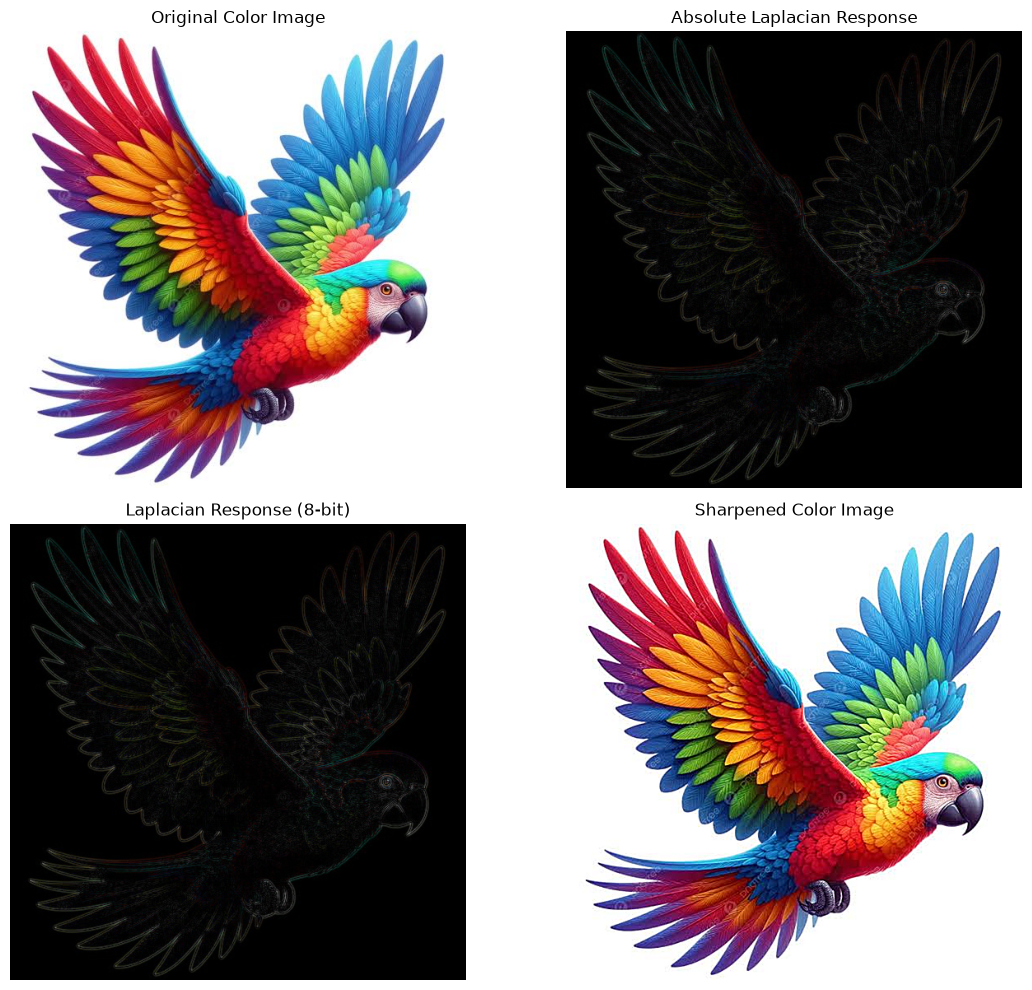

In [3]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian separately to the RGB channels
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Create an 8-bit visualization of the absolute response
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Sharpen using the signed Laplacian response.
# Convert to a signed type and clip to prevent uint8 overflow.
finalImage2 = np.clip(
    img.astype(np.float64) - laplacian,
    0, 255
).astype(np.uint8)

# 5. Display color images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img), plt.title('Original Color Image'), plt.axis('off')
plt.subplot(222), plt.imshow(laplacian_8bit), plt.title('Absolute Laplacian Response'), plt.axis('off')
plt.subplot(223), plt.imshow(laplacian_8bit), plt.title('Laplacian Response (8-bit)'), plt.axis('off')
plt.subplot(224), plt.imshow(finalImage2), plt.title('Sharpened Color Image'), plt.axis('off')
plt.tight_layout()
plt.show()
